# Movie Recommendations

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Recommend movies using user interaction and film metadata.

**Approach:** Pandas-based exploration and recommendation methods.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Recommendation System  </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE


## Step 1: Import Libraries
First, we need to import the necessary libraries.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

###  Import Libraries and Load Dataset
In this step, we'll import the required Python libraries (`pandas`, `matplotlib`, `seaborn`) and load the MovieLens dataset (`movies.csv`, `ratings.csv`, `tags.csv`, `links.csv`) into DataFrames for analysis.


In [10]:
# Set Seaborn style
sns.set_theme(style="whitegrid")

# Load the datasets
movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings.csv")
tags = pd.read_csv("tags.csv")
links = pd.read_csv("links.csv")

# Display the first few rows of each dataset
print("Movies Dataset:\n", movies.head())
print("\nRatings Dataset:\n", ratings.head())
print("\nTags Dataset:\n", tags.head())
print("\nLinks Dataset:\n", links.head())

Movies Dataset:
    movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  

Ratings Dataset:
    userId  movieId  rating  timestamp
0       1       17     4.0  944249077
1       1       25     1.0  944250228
2       1       29     2.0  943230976
3       1       30     5.0  944249077
4       1       32     5.0  943228858

Tags Dataset:
    userId  movieId          tag   timestamp
0      22    26479  Kevin Kline  1583038886
1      22    79592     misogyny  1581

### Top Movies by Ratings Count
Here, we'll identify the top 10 movies with the highest number of ratings. This will give us insights into which movies are the most popular among users.


Top 10 Movies by Number of Ratings:
                                                title  rating
0                   Shawshank Redemption, The (1994)  102929
1                                Forrest Gump (1994)  100296
2                                Pulp Fiction (1994)   98409
3                                 Matrix, The (1999)   93808
4                   Silence of the Lambs, The (1991)   90330
5          Star Wars: Episode IV - A New Hope (1977)   85010
6                                  Fight Club (1999)   77332
7                               Jurassic Park (1993)   75233
8                            Schindler's List (1993)   73849
9  Lord of the Rings: The Fellowship of the Ring,...   73122


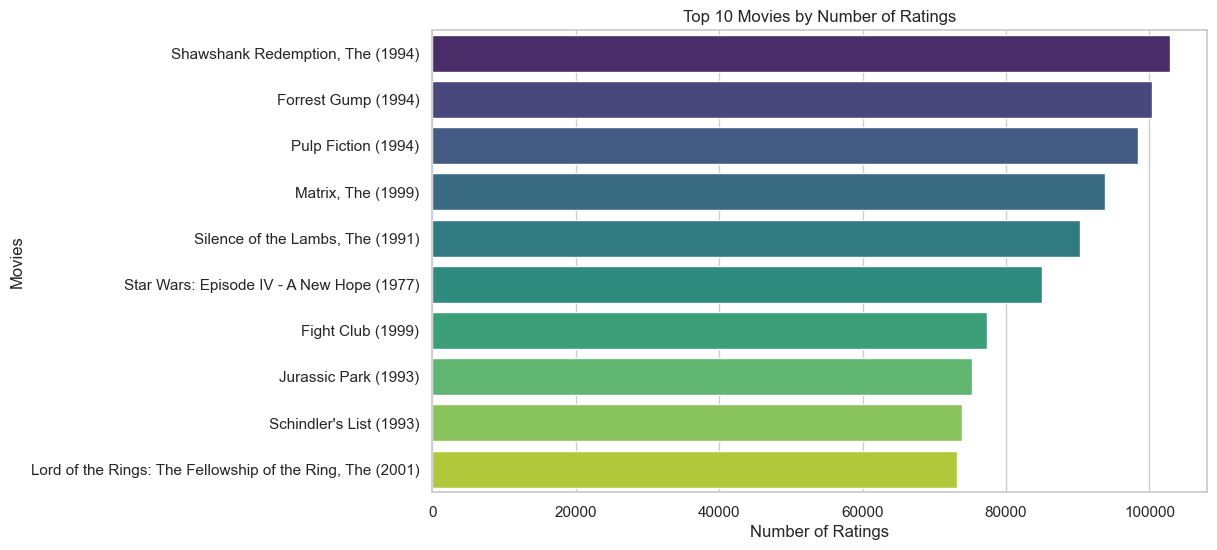

In [11]:
# Group by movieId and count ratings
top_rated_movies = (
    ratings.groupby("movieId")["rating"]
    .count()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Merge with movies DataFrame to get movie titles
top_rated_movies = top_rated_movies.merge(movies, on="movieId", how="left")

# Display the results
print("Top 10 Movies by Number of Ratings:\n", top_rated_movies[["title", "rating"]])

# Visualize the top-rated movies
plt.figure(figsize=(10, 6))
sns.barplot(
    y="title", x="rating", data=top_rated_movies, palette="viridis"
)
plt.title("Top 10 Movies by Number of Ratings")
plt.xlabel("Number of Ratings")
plt.ylabel("Movies")
plt.show()


### Top Movies by Average Ratings
Next, we'll calculate the average rating for each movie and identify the top 10 movies with the highest average rating. This will help us understand user preferences for highly-rated movies.


Top 10 Movies by Average Rating:
                                                    title  average_rating
57193          Franco Escamilla: For the Anecdote (2018)             5.0
77007                Rebuilding a Dream Christmas (2021)             5.0
44589                              Without Family (1984)             5.0
76896                            Time of the Gods (1992)             5.0
76900  A Godwink Christmas: Second Chance, First Love...             5.0
76904                               Amazed By You (2018)             5.0
24608                          The Bates Haunting (2013)             5.0
67403                            It Feels So Good (2019)             5.0
34411         The King and Queen of Moonlight Bay (2003)             5.0
76998            Paul McCartney: Back in the U.S. (2002)             5.0


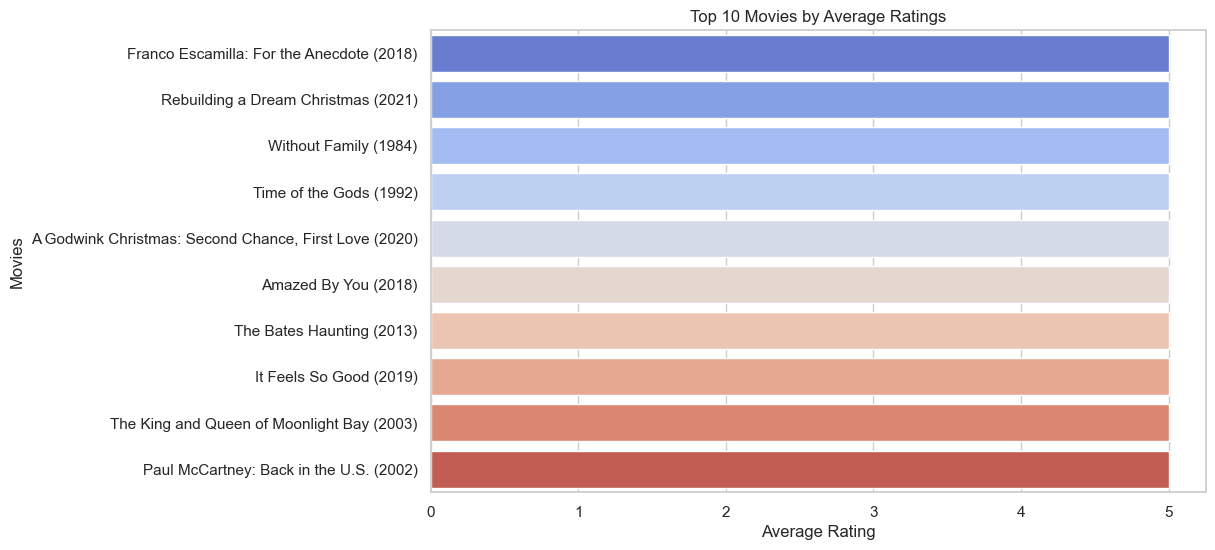

In [12]:
# Calculate average ratings for each movie
average_ratings = (
    ratings.groupby("movieId")["rating"]
    .mean()
    .reset_index()
    .rename(columns={"rating": "average_rating"})
)

# Merge with movies DataFrame to get movie titles
average_ratings = average_ratings.merge(movies, on="movieId", how="left")

# Display the results
top_average_rated = average_ratings.sort_values("average_rating", ascending=False).head(10)
print("Top 10 Movies by Average Rating:\n", top_average_rated[["title", "average_rating"]])

# Visualize the results
plt.figure(figsize=(10, 6))
sns.barplot(
    y="title", x="average_rating", data=top_average_rated, palette="coolwarm"
)
plt.title("Top 10 Movies by Average Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Movies")
plt.show()


### Distribution of Ratings
We'll plot a histogram to visualize the distribution of user ratings. This helps us understand the spread and central tendency of ratings across all movies.


C:\Users\Dingue\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


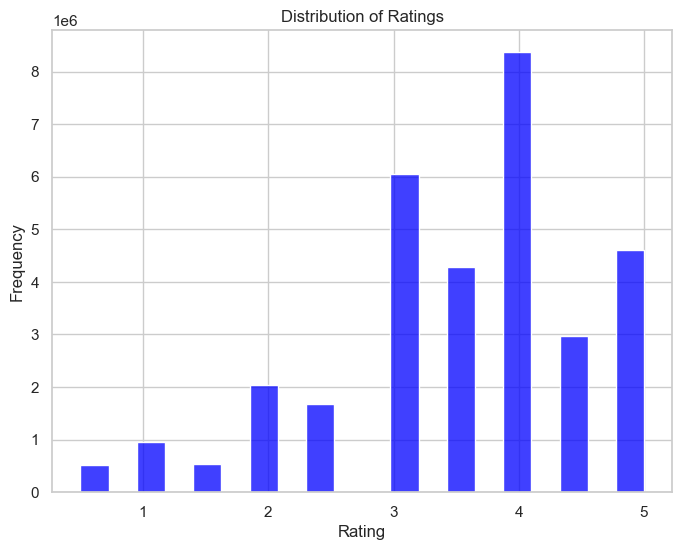

In [13]:
# Plot the distribution of ratings
plt.figure(figsize=(8, 6))
sns.histplot(ratings["rating"], bins=20, kde=False, color="blue")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()


### Top Genres by Popularity
Using the genres column, we'll split the genres into individual values and identify the most common genres based on their frequency.


Top Genres by Frequency:
 genres_list
Drama                 34175
Comedy                23124
Thriller              11823
Romance               10369
Action                 9668
Documentary            9363
Horror                 8654
(no genres listed)     7080
Crime                  6976
Adventure              5402
Name: count, dtype: int64


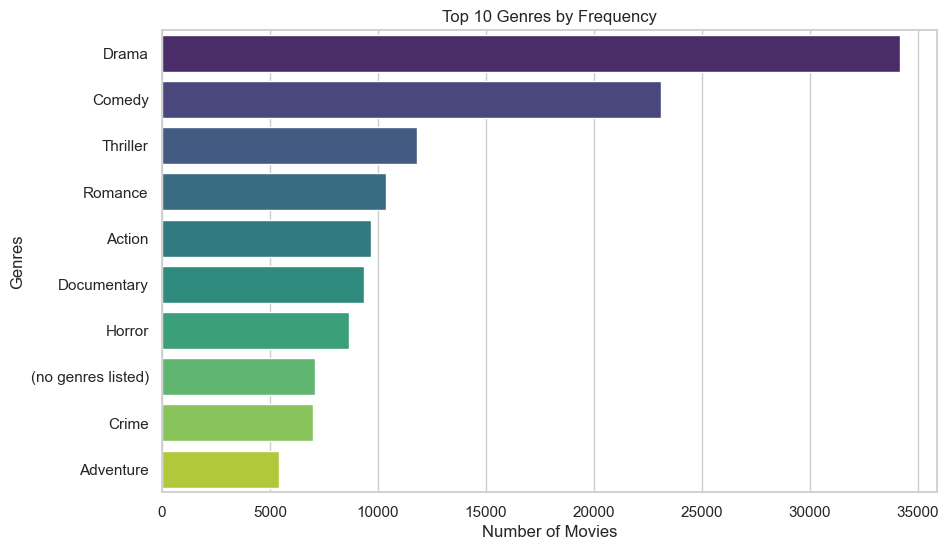

In [7]:
# Split the genres column into a list and count occurrences
movies["genres_list"] = movies["genres"].str.split("|")
all_genres = movies["genres_list"].explode()
top_genres = all_genres.value_counts().head(10)

# Display the results
print("Top Genres by Frequency:\n", top_genres)

# Visualize the results
plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, palette="viridis")
plt.title("Top 10 Genres by Frequency")
plt.xlabel("Number of Movies")
plt.ylabel("Genres")
plt.show()


### Top Tags
We'll examine the most frequently used tags in the dataset to identify common themes or keywords associated with movies.


Top Tags:
 tag
sci-fi                10996
atmospheric            9589
action                 8473
comedy                 8139
funny                  7467
surreal                7231
visually appealing     7090
based on a book        6617
twist ending           6521
dark comedy            6053
Name: count, dtype: int64


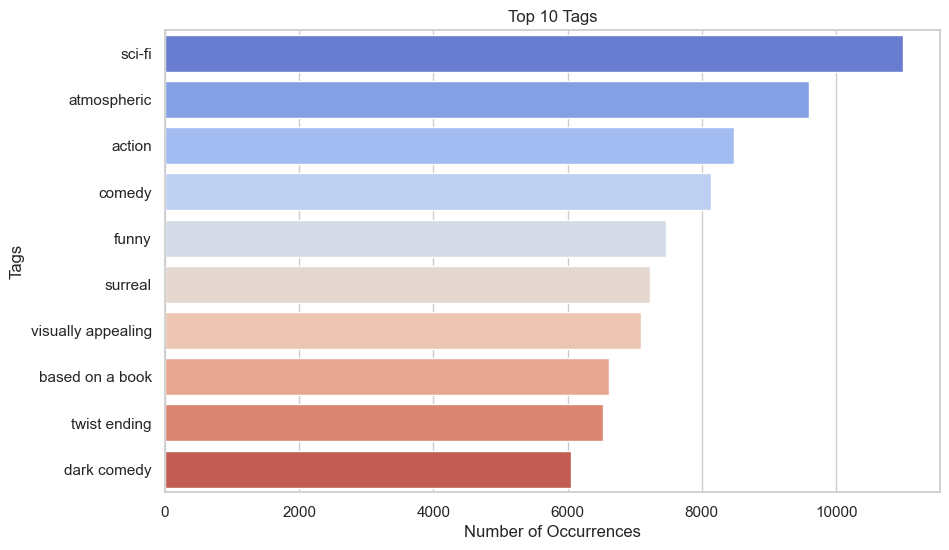

In [14]:
# Count occurrences of tags
top_tags = tags["tag"].value_counts().head(10)

# Display the results
print("Top Tags:\n", top_tags)

# Visualize the results
plt.figure(figsize=(10, 6))
sns.barplot(x=top_tags.values, y=top_tags.index, palette="coolwarm")
plt.title("Top 10 Tags")
plt.xlabel("Number of Occurrences")
plt.ylabel("Tags")
plt.show()


# Correlation Between Number of Ratings and Average Rating
We'll analyze whether there's a correlation between the number of ratings a movie receives and its average rating. This helps us understand if popular movies tend to be rated higher or lower.


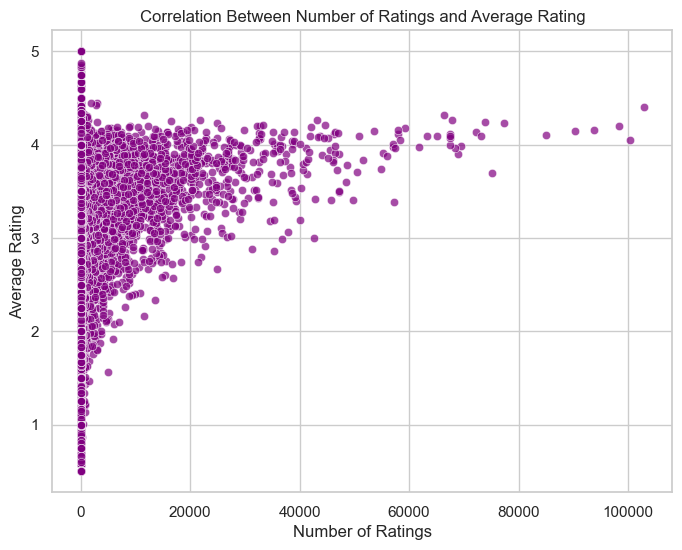

In [15]:
# Calculate total ratings and average rating for each movie
movie_ratings = ratings.groupby("movieId").agg(
    total_ratings=("rating", "count"), average_rating=("rating", "mean")
)

# Plot a scatterplot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="total_ratings", y="average_rating", data=movie_ratings, alpha=0.7, color="purple"
)
plt.title("Correlation Between Number of Ratings and Average Rating")
plt.xlabel("Number of Ratings")
plt.ylabel("Average Rating")
plt.show()
